# 02 · Caso 1 — poço offshore único: rede, digrafo e simulação

Reprodução da Seção 4.1 do artigo: Tabelas 2–6, Figs. 3–5 (topologia e digrafo) e
Figs. 6–8 (curvas de nível da pressão de fundo e da pressão de injeção de gás).

A rede é construída com a API do pacote `gaslift`: nós e linhas da rede de coleta mais um
modelo de poço (`WellDesign`) que se expande em 6 nós e 6 linhas (Fig. 5).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
FIG = ROOT / "docs" / "paper" / "figures"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from gaslift import case1_single_well, SimulationOptions, ModelOptions, IntegrationOptions
from gaslift.plotting import plot_case_topology, plot_digraph, plot_rate_contours, plot_pressure_path
from gaslift.sweeps import sweep_rates

case = case1_single_well(q_oil=10.0, q_gas=2.0)
net = case.network
print(net)
print(f"Unknowns / equations: 3N + 4S = {net.layout.size}  (N = {net.n_nodes}, S = {net.n_pipes});"
      f" specifications: {case.specifications.count}")

Network(name='Case 1 - offshore single well', nodes=10, pipes=9, wells=1)
Unknowns / equations: 3N + 4S = 66  (N = 10, S = 9); specifications: 19


## Tabelas 2, 3 e 4 · Linhas da rede e perfis das linhas 2 e 8

In [3]:
from gaslift.units import INCH

def pipes_table(case):
    net = case.network
    rows = []
    for p in net.pipes:
        g = p.geometry
        angles = np.degrees(g.segment_angles)
        incl = f"{angles[0]:.0f}°" if np.allclose(angles, angles[0]) else "profile"
        rows.append({"Line": case.paper_pipe_numbers[p.name], "Name": p.name, "Type": p.category.value,
                     "Diameter (in)": g.inlet_diameter / INCH, "Length (m)": g.length,
                     "Inclination": incl, "Roughness (µm)": g.roughness[0] * 1e6})
    return pd.DataFrame(rows).set_index("Line")

def nodes_table(case):
    net = case.network
    rows = [{"Node": case.paper_node_numbers[n.name], "Name": n.name, "Role": n.role.value,
             "X (m)": n.x, "Y (m)": n.y, "Height (m)": n.z} for n in net.nodes]
    return pd.DataFrame(rows).set_index("Node")

def profile_table(case, pipe):
    g = case.network.pipe(pipe).geometry
    return pd.DataFrame({"Length (m)": g.cumulative_lengths, "Height (m)": g.points[:, 2],
                         "x (m)": g.points[:, 0], "y (m)": g.points[:, 1]}).T

def specs_table(case):
    rows = []
    for name, s in case.specifications.items():
        parts = []
        if s.pressure is not None: parts.append(f"P = {s.pressure / 1e5:g} bar")
        if s.liquid_flow is not None: parts.append(f"wL = {s.liquid_flow:g} kg/s")
        if s.gas_flow is not None: parts.append(f"wG = {s.gas_flow:g} kg/s")
        rows.append({"Node": case.paper_node_numbers[name], "Name": name, "Specifications": "; ".join(parts)})
    return pd.DataFrame(rows).set_index("Node")

pipes_table(case)

,Name,Type,Diameter (in),Length (m),Inclination,Roughness (µm)
Line,,,,,,
1,production_line_1,production,6.0000,1500.0000,0°,100.0
2,production_line_2,production,6.0000,2504.9876,profile,100.0
3,riser,production,6.0000,1500.0000,90°,100.0
4,well_1:flowline,flowline,4.0000,500.0000,0°,100.0
5,well_1:wellbore_upper,wellbore,4.0000,1710.0000,90°,100.0
6,well_1:wellbore_lower,wellbore,4.0000,338.0000,90°,100.0
7,well_1:annulus,annulus,8.2857,1710.0000,90°,100.0
8,well_1:gas_line_1,gas,2.0000,4505.0126,profile,0.0
9,well_1:gas_line_2,gas,2.0000,1515.0000,-90°,0.0


> Os valores seguem os scripts MATLAB que geraram os resultados publicados (`case_03.m`):
> coluna de produção de 4 in, anular de 1710 m, trecho inferior de 338 m e rugosidade nula
> nas linhas de gás. A Tabela 2 impressa no artigo lista 5 in, 1500 m, 300 m e 100 µm —
> ver `docs/paper_vs_code.md`.

In [4]:
display(profile_table(case, "production_line_2").rename_axis("Line 2 (Table 3)"))
display(profile_table(case, "well_1:gas_line_1").rename_axis("Line 8 (Table 4)"))

,0,1,2
Line 2 (Table 3),,,
Length (m),0.0,1500.0,2504.9876
Height (m),-1400.0,-1400.0,-1500.0000
x (m),0.0,0.0,0.0000
y (m),1500.0,3000.0,4000.0000


,0,1,2,3,4
Line 8 (Table 4),,,,,
Length (m),0.0,1004.9876,2504.9876,4004.9876,4505.0126
Height (m),-1495.0,-1395.0000,-1395.0000,-1395.0000,-1400.0000
x (m),0.0,0.0000,0.0000,0.0000,400.0000
y (m),4000.0,3000.0000,1500.0000,0.0000,-300.0000


## Tabelas 5 e 6 · Nós e especificações

In [5]:
display(nodes_table(case))
display(specs_table(case))

,Name,Role,X (m),Y (m),Height (m)
Node,,,,,
1,manifold_1,connection,0.0,0.0,-1400.0
2,manifold_2,connection,0.0,1500.0,-1400.0
3,riser_base,connection,0.0,4000.0,-1500.0
4,riser_top,outlet,0.0,4000.0,0.0
5,well_1:wellhead,wellhead,400.0,-300.0,-1400.0
6,well_1:injection_point,injection_point,400.0,-300.0,-3110.0
7,well_1:downhole,downhole,400.0,-300.0,-3448.0
8,well_1:annulus_top,annulus_top,400.0,-300.0,-1400.0
9,well_1:gas_junction,gas_junction,0.0,4000.0,-1495.0


,Name,Specifications
Node,,
1,manifold_1,wL = 0 kg/s; wG = 0 kg/s
2,manifold_2,wL = 0 kg/s; wG = 0 kg/s
3,riser_base,wL = 0 kg/s; wG = 0 kg/s
4,riser_top,P = 15 bar
5,well_1:wellhead,wL = 0 kg/s; wG = 0 kg/s
6,well_1:injection_point,wL = 0 kg/s; wG = 0 kg/s
7,well_1:downhole,wL = 10 kg/s; wG = 1e-06 kg/s
8,well_1:annulus_top,wL = 0 kg/s; wG = 0 kg/s
9,well_1:gas_junction,wL = 0 kg/s; wG = 0 kg/s


## Fig. 3 · Projeção isométrica

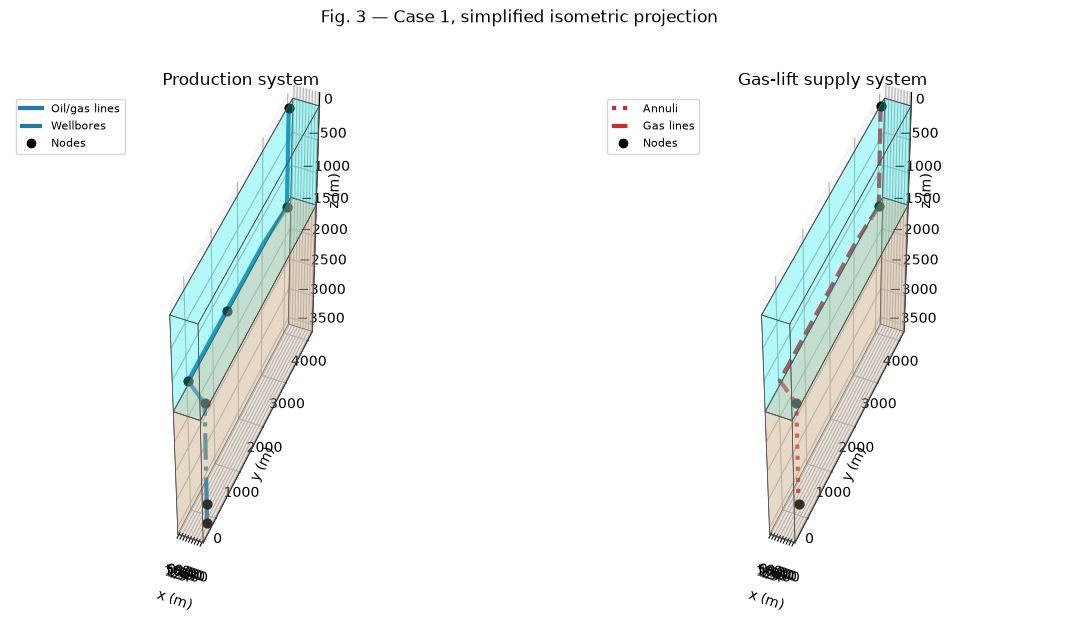

In [6]:
fig = plot_case_topology(net)
fig.suptitle("Fig. 3 — Case 1, simplified isometric projection", y=1.02);

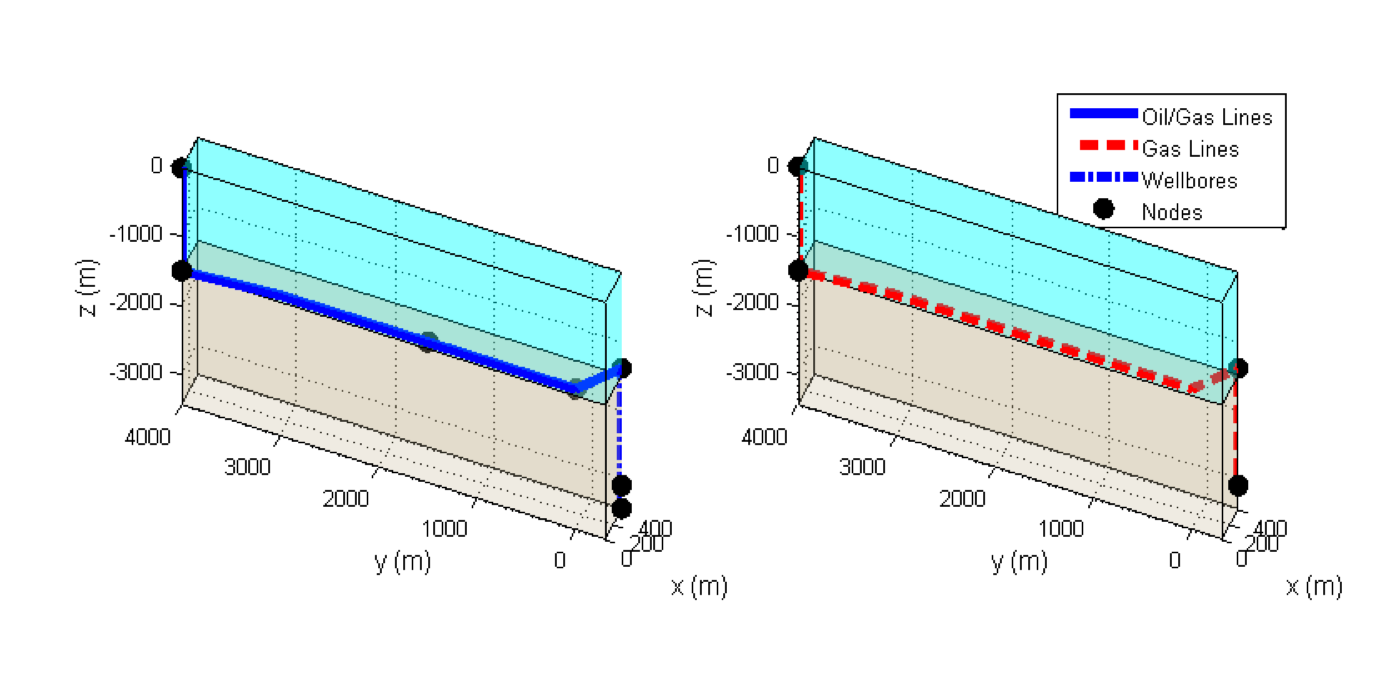

In [7]:
display(Image(filename=str(FIG / "FIG_03.png"), width=900))

## Figs. 4 e 5 · Digrafo da rede e do poço

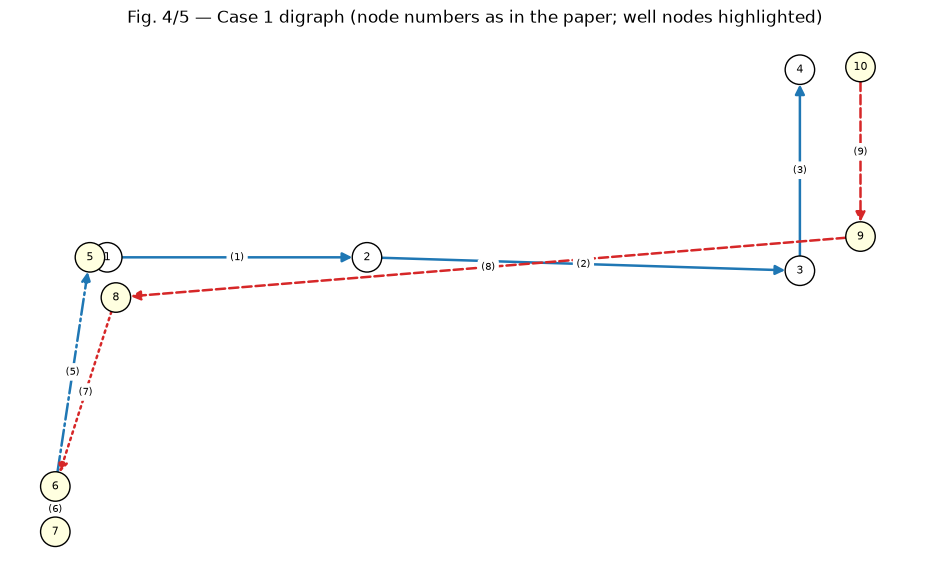

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
plot_digraph(net, ax, node_numbers=case.paper_node_numbers, pipe_numbers=case.paper_pipe_numbers)
ax.set_title("Fig. 4/5 — Case 1 digraph (node numbers as in the paper; well nodes highlighted)");

In [9]:
M = net.incidence_matrix()
pd.DataFrame(M.astype(int), index=[f"node {i+1}" for i in range(net.n_nodes)], columns=[f"line {j+1}" for j in range(net.n_pipes)])

,line 1,line 2,line 3,line 4,line 5,line 6,line 7,line 8,line 9
node 1,-1,0,0,1,0,0,0,0,0
node 2,1,-1,0,0,0,0,0,0,0
node 3,0,1,-1,0,0,0,0,0,0
node 4,0,0,1,0,0,0,0,0,0
node 5,0,0,0,-1,1,0,0,0,0
node 6,0,0,0,0,-1,1,1,0,0
node 7,0,0,0,0,0,-1,0,0,0
node 8,0,0,0,0,0,0,-1,1,0
node 9,0,0,0,0,0,0,0,-1,1
node 10,0,0,0,0,0,0,0,0,-1


## Uma simulação: 10 kg/s de óleo e 2 kg/s de gás

O estado estacionário é obtido por Newton–Raphson a partir da estimativa do modelo linear
laminar (Seção 3.4). Abaixo, as tabelas de nós, linhas e poço, e os perfis de pressão ao
longo do caminho de produção (fundo do poço → riser) e do caminho do gás (plataforma →
ponto de injeção).

In [10]:
sim = case.simulator()
sol = sim.solve()
print(sol.status)
display(sol.wells_table().T)
display(sol.nodes_table())

converged (residual below tolerance) after 3 iterations, |F| = 3.118e-11, 0.06 s


well,well_1
oil_rate_kg_s,10.0000
gas_injection_kg_s,2.0000
downhole_pressure_bar,213.8629
injection_point_pressure_bar,184.7259
wellhead_pressure_bar,84.8856
gas_inlet_pressure_bar,278.2010


,role,x_m,y_m,z_m,pressure_bar,liquid_inflow_kg_s,gas_inflow_kg_s
node,,,,,,,
manifold_1,connection,0.0,0.0,-1400.0,75.9028,0.0000e+00,0.0000e+00
manifold_2,connection,0.0,1500.0,-1400.0,71.9264,-0.0000e+00,0.0000e+00
riser_base,connection,0.0,4000.0,-1500.0,68.2634,-0.0000e+00,0.0000e+00
riser_top,outlet,0.0,4000.0,0.0,15.0000,-1.0000e+01,-2.0000e+00
well_1:wellhead,wellhead,400.0,-300.0,-1400.0,84.8856,0.0000e+00,0.0000e+00
well_1:injection_point,injection_point,400.0,-300.0,-3110.0,184.7259,0.0000e+00,0.0000e+00
well_1:downhole,downhole,400.0,-300.0,-3448.0,213.8629,1.0000e+01,1.0000e-06
well_1:annulus_top,annulus_top,400.0,-300.0,-1400.0,207.8969,0.0000e+00,0.0000e+00
well_1:gas_junction,gas_junction,0.0,4000.0,-1495.0,295.9956,0.0000e+00,0.0000e+00


In [11]:
sol.pipes_table()

,category,from,to,length_m,diameter_in,liquid_flow_kg_s,gas_flow_kg_s,inlet_pressure_bar,outlet_pressure_bar,pressure_drop_bar,mean_liquid_holdup,dominant_pattern
pipe,,,,,,,,,,,,
production_line_1,production,manifold_1,manifold_2,1500.0000,6.0000,1.0000e+01,2.0000e+00,75.9028,71.9264,3.9763,4.0959e-01,intermittent
production_line_2,production,manifold_2,riser_base,2504.9876,6.0000,1.0000e+01,2.0000e+00,71.9264,68.2634,3.6630,3.6952e-01,intermittent
riser,production,riser_base,riser_top,1500.0000,6.0000,1.0000e+01,2.0000e+00,68.2634,15.0000,53.2634,3.3723e-01,intermittent
well_1:flowline,flowline,well_1:wellhead,manifold_1,500.0000,4.0000,1.0000e+01,2.0000e+00,84.8856,75.9028,8.9828,4.0660e-01,intermittent
well_1:wellbore_upper,wellbore,well_1:injection_point,well_1:wellhead,1710.0000,4.0000,1.0000e+01,2.0000e+00,184.7259,84.8856,99.8403,4.8023e-01,intermittent
well_1:wellbore_lower,wellbore,well_1:downhole,well_1:injection_point,338.0000,4.0000,1.0000e+01,1.0000e-06,213.8629,184.7259,29.1370,1.0000e+00,distributed
well_1:annulus,annulus,well_1:annulus_top,well_1:injection_point,1710.0000,8.2857,1.0000e-06,2.0000e+00,207.8969,184.7259,23.1711,1.2942e-03,segregated
well_1:gas_line_1,gas,well_1:gas_junction,well_1:annulus_top,4505.0126,2.0000,1.0000e-06,2.0000e+00,295.9956,207.8969,88.0987,6.8010e-05,distributed
well_1:gas_line_2,gas,well_1:gas_inlet,well_1:gas_junction,1515.0000,2.0000,1.0000e-06,2.0000e+00,278.2010,295.9956,-17.7946,1.0000e-06,distributed


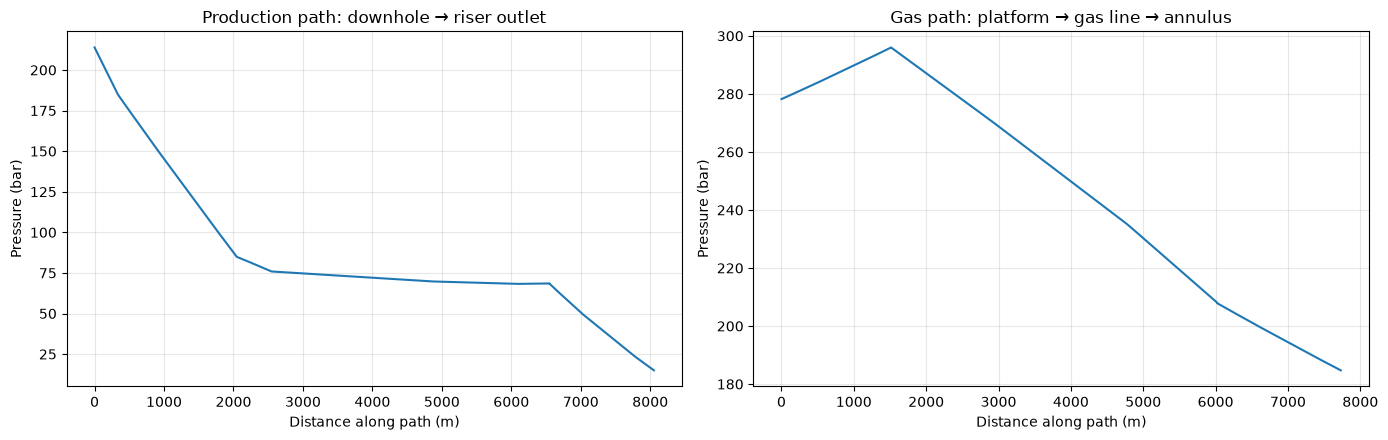

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_pressure_path(sol, ["well_1:wellbore_lower", "well_1:wellbore_upper", "well_1:flowline", "production_line_1", "production_line_2", "riser"], axes[0])
axes[0].set_title("Production path: downhole → riser outlet")
plot_pressure_path(sol, ["well_1:gas_line_2", "well_1:gas_line_1", "well_1:annulus"], axes[1])
axes[1].set_title("Gas path: platform → gas line → annulus")
plt.tight_layout()

## Figs. 6 e 7 · Varredura de vazões (linhas de gás de 2 in)

O artigo varre a vazão de gás injetado (0,5 a 4 kg/s) e a vazão de óleo (0,5 a 20 kg/s).
Os resultados originais desta varredura foram gerados com tolerância relativa `1e-3` na
integração (`results_Subsea_1_2.mat`), por isso usamos o mesmo valor aqui. A varredura
percorre a grade em serpentina com partida quente, como o script original.

In [13]:
q_gas = np.arange(0.5, 4.01, 0.5)
q_oil = np.concatenate([[0.5], np.arange(1.0, 20.01, 1.0)])
opts = SimulationOptions(model=ModelOptions(integration=IntegrationOptions(rtol=1e-3)), compute_profiles=False)
import time
t0 = time.perf_counter()
sweep = sweep_rates(case1_single_well(), q_gas, q_oil, opts)
print(f"{sweep.converged.sum()} of {sweep.converged.size} points converged in {time.perf_counter() - t0:.1f} s")

167 of 168 points converged in 30.8 s


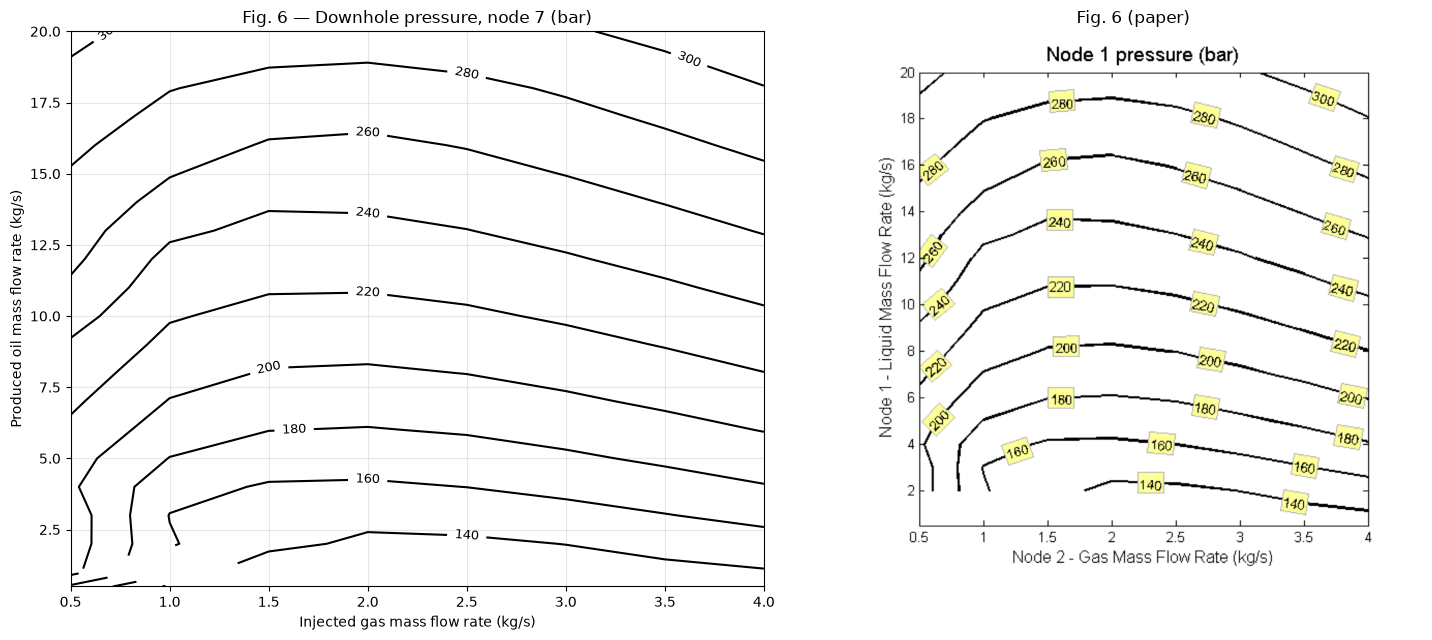

In [14]:
levels = np.arange(140, 320, 20)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.downhole(0), axes[0], levels, title="Fig. 6 — Downhole pressure, node 7 (bar)")
axes[1].imshow(plt.imread(FIG / "FIG_06.png")); axes[1].axis("off"); axes[1].set_title("Fig. 6 (paper)")
plt.tight_layout()

A "pressão de entrada do gas lift" dos gráficos do artigo é lida no nó 9 (interconexão das
linhas de gás na base do riser, −1495 m), que é o nó apontado pelo índice `ix_Pgaslift` do
código original — e não no nó 10 (plataforma), como descreve o texto. A diferença entre os
dois nós é a coluna hidrostática de gás da linha vertical de 1515 m.

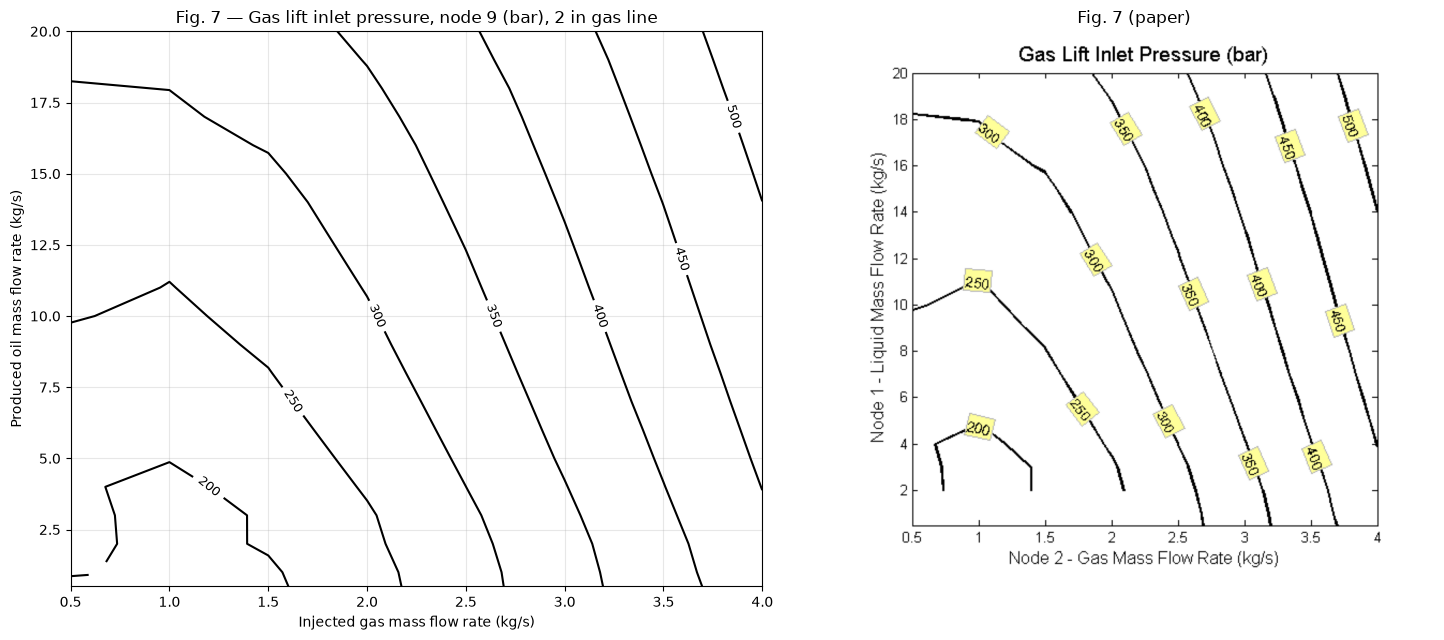

In [15]:
levels = np.arange(200, 560, 50)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.gas_junction(0), axes[0], levels, title="Fig. 7 — Gas lift inlet pressure, node 9 (bar), 2 in gas line")
axes[1].imshow(plt.imread(FIG / "FIG_07.png")); axes[1].axis("off"); axes[1].set_title("Fig. 7 (paper)")
plt.tight_layout()

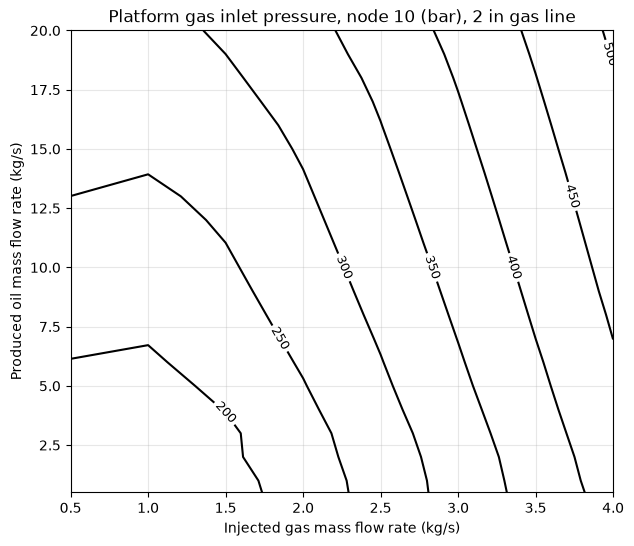

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.gas_inlet(0), ax, np.arange(150, 560, 50), title="Platform gas inlet pressure, node 10 (bar), 2 in gas line");

## Fig. 8 · Linhas de gás de 3 in

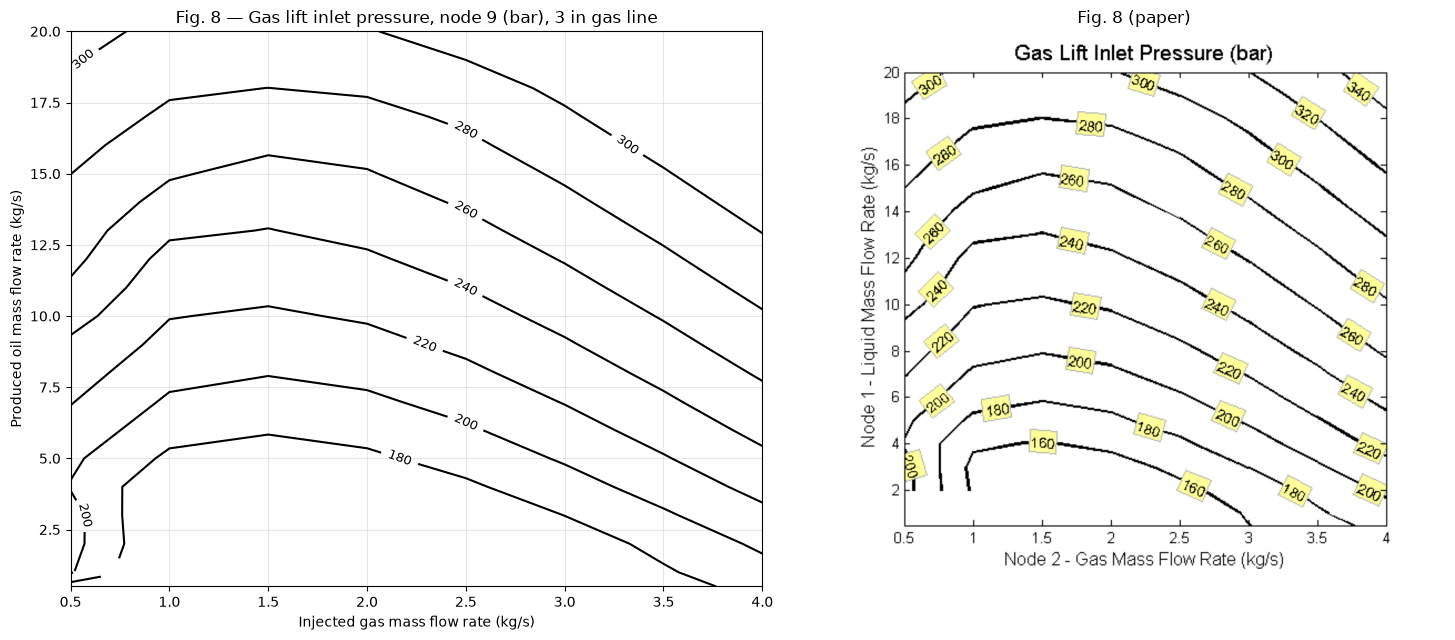

In [17]:
sweep3 = sweep_rates(case1_single_well(gas_line_diameter_in=3.0), q_gas, q_oil, opts)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_rate_contours(sweep3.q_gas, sweep3.q_oil, sweep3.gas_junction(0), axes[0], np.arange(180, 320, 20), title="Fig. 8 — Gas lift inlet pressure, node 9 (bar), 3 in gas line")
axes[1].imshow(plt.imread(FIG / "FIG_08.png")); axes[1].axis("off"); axes[1].set_title("Fig. 8 (paper)")
plt.tight_layout()

## Leitura da Fig. 6 (texto do artigo)

> "considering a downhole pressure of 220 bar, to produce 10.0 kg/s of petroleum it is
> necessary to inject 1.0 kg/s of gas or a higher value of gas flow rate, equal to 2.7 kg/s
> [...] at downhole pressure of 220 bar, the maximum oil production is 10.7 kg/s with gas
> injection of 1.8 kg/s."

In [18]:
from scipy.interpolate import RegularGridInterpolator

interp = RegularGridInterpolator((sweep.q_oil, sweep.q_gas), sweep.downhole(0), bounds_error=False)
qg_fine = np.linspace(0.5, 4.0, 701)
p_at_10 = interp(np.column_stack([np.full_like(qg_fine, 10.0), qg_fine]))
roots = qg_fine[np.flatnonzero(np.diff(np.sign(p_at_10 - 220.0)))]
print("gas rates giving 220 bar at 10 kg/s of oil:", np.round(roots, 2), "kg/s")

qo_fine = np.linspace(0.5, 20.0, 781)
QO, QG = np.meshgrid(qo_fine, qg_fine, indexing="ij")
P = interp(np.column_stack([QO.ravel(), QG.ravel()])).reshape(QO.shape)
feasible = np.where(P <= 220.0, QO, np.nan)
i, j = np.unravel_index(np.nanargmax(feasible), feasible.shape)
print(f"maximum oil at 220 bar: {qo_fine[i]:.2f} kg/s with {qg_fine[j]:.2f} kg/s of gas")

gas rates giving 220 bar at 10 kg/s of oil: [1.12 2.77] kg/s
maximum oil at 220 bar: 10.83 kg/s with 2.00 kg/s of gas


## Validação contra os resultados MATLAB originais

In [19]:
import json
ref = json.load(open(REF / "case1_grid_2in.json"))
ref_p = np.array([[c[0] if c else np.nan for c in row] for row in ref["p_downhole_bar"]], dtype=float)
ref_pg = np.array([[c[0] if c else np.nan for c in row] for row in ref["p_gasinlet_bar"]], dtype=float)
diff_p = np.abs(sweep.downhole(0) - ref_p)
diff_pg = np.abs(sweep.gas_junction(0) - ref_pg)
print(f"MATLAB reference: {np.isfinite(ref_p).sum()} converged points; Python: {sweep.converged.sum()}")
print(f"max |ΔP_downhole| = {np.nanmax(diff_p):.2e} bar, max |ΔP_gas| = {np.nanmax(diff_pg):.2e} bar over common points")
pd.DataFrame(diff_p, index=sweep.q_oil, columns=sweep.q_gas).rename_axis(index="q_oil", columns="q_gas").style.format("{:.1e}")

MATLAB reference: 166 converged points; Python: 167
max |ΔP_downhole| = 2.31e-08 bar, max |ΔP_gas| = 7.36e-08 bar over common points


q_gas,0.500000,1.000000,1.500000,2.000000,2.500000,3.000000,3.500000,4.000000
q_oil,,,,,,,,
0.500000,1.3e-09,3.6e-09,6.4e-09,1.1e-08,1.2e-08,1.4e-08,1.6e-08,1.8e-08
1.000000,1.4e-09,nan,7.2e-09,nan,1.8e-08,1.7e-08,1.7e-08,1.9e-08
2.000000,1.4e-09,1.0e-08,7.6e-09,1.0e-08,1.2e-08,1.5e-08,1.8e-08,1.8e-08
3.000000,1.3e-09,4.2e-09,6.1e-09,9.7e-09,1.1e-08,1.3e-08,1.6e-08,1.6e-08
4.000000,2.2e-09,3.4e-09,6.1e-09,8.8e-09,1.1e-08,1.4e-08,1.6e-08,1.9e-08
5.000000,1.1e-09,3.5e-09,6.3e-09,9.1e-09,1.2e-08,1.4e-08,1.7e-08,1.9e-08
6.000000,1.1e-09,3.5e-09,6.4e-09,9.3e-09,1.2e-08,1.5e-08,1.7e-08,1.9e-08
7.000000,1.1e-09,3.5e-09,6.5e-09,9.4e-09,1.3e-08,1.5e-08,1.8e-08,2.0e-08
8.000000,1.1e-09,3.5e-09,6.5e-09,9.6e-09,1.2e-08,1.5e-08,1.8e-08,2.1e-08
